# 实验报告02：NumPy、SciPy、Matplotlib 与 pandas 数据处理

In [6]:
import os
import uuid
import hashlib
import platform
import numpy as np
import scipy
import matplotlib
import pandas as pd
# 修改为自己的学号
STUDENT_ID = 20244080302
CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV", "base")
print(f"[Conda 环境] {CONDA_ENV}")
MACHINE_FP = hashlib.sha256(
 f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号] {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")

[Conda 环境] HRRR
[学号] 20244080302
[机器指纹] c203dca07a7d4af6
[RUN_ID] 20244080302-c203dca07a7d4af6


# 实验1：NumPy 数组、数据类型与索引
操作任务：
1. 分别创建整数、浮点数和布尔值 ndarray，输出每个数组的 dtype、shape 和
ndim。解释 NumPy 数组的数据类型与 Python 列表的差别。
2. ⽤ np.arange(12) 创建⼀维数组，并分别变为形状 (3, 4) 和 (2, 3, 2) 的
数组。展⽰数组内容，说明改变形状时元素总数必须满⾜什么条件。
3. 对形状为 (3, 4) 的数组完成以下索引：取第 2 ⾏、取第 1 ⾄第 3 列、取⼤于 6
的元素，并分别输出结果及其形状。
4. 使⽤ np.arange(10) 分别选出“⼩于 2 或⼤于 7”和“⼤于 3 且⼩于 7”的元素。使
⽤括号配合 |、& 或 np.logical_or()、np.logical_and()。
5. 构造两个形状为 (2, 2) 的数组，对⽐ *、np.multiply() 与 @、
np.matmul() 的结果，说明逐元素乘法与矩阵乘法的区别。

In [15]:
import numpy as np

print("任务 1：三种 dtype 的 ndarray")

a_int = np.array([1, 2, 3, 4])
a_float = np.array([1.0, 2.5, 3.75])
a_bool = np.array([True, False, True])

for name, arr in [("整数数组", a_int), ("浮点数组", a_float), ("布尔数组", a_bool)]:
    print(f"{name}: {arr}")
    print(f"    dtype = {arr.dtype}, shape = {arr.shape}, ndim = {arr.ndim}")

# 混合类型会自动向上转型
print("混合 [1, 2.5, True] ->", np.array([1, 2.5, True]).dtype)

print("""
说明：
- NumPy 数组是同构的（homogeneous），所有元素共享同一个 dtype，
  在内存中连续存放，因此运算快、占用小；
- Python 列表是异构的，每个元素都是独立的对象（含类型信息），
  支持动态增删，但逐元素运算需要 Python 循环，速度慢；
- 所以 np.array([1, 2, 3]) * 2 是逐元素数值运算，
  而 [1, 2, 3] * 2 只是列表重复。
""")


任务 1：三种 dtype 的 ndarray
整数数组: [1 2 3 4]
    dtype = int64, shape = (4,), ndim = 1
浮点数组: [1.   2.5  3.75]
    dtype = float64, shape = (3,), ndim = 1
布尔数组: [ True False  True]
    dtype = bool, shape = (3,), ndim = 1
混合 [1, 2.5, True] -> float64

说明：
- NumPy 数组是同构的（homogeneous），所有元素共享同一个 dtype，
  在内存中连续存放，因此运算快、占用小；
- Python 列表是异构的，每个元素都是独立的对象（含类型信息），
  支持动态增删，但逐元素运算需要 Python 循环，速度慢；
- 所以 np.array([1, 2, 3]) * 2 是逐元素数值运算，
  而 [1, 2, 3] * 2 只是列表重复。



In [11]:
import numpy as np

print("任务 2：reshape")

base = np.arange(12)
arr_34 = base.reshape(3, 4)
arr_232 = base.reshape(2, 3, 2)

print("原一维数组 base (shape=%s, ndim=%d):" % (base.shape, base.ndim))
print(base)
print("\nreshape(3, 4)  shape=%s, ndim=%d:" % (arr_34.shape, arr_34.ndim))
print(arr_34)
print("\nreshape(2, 3, 2)  shape=%s, ndim=%d:" % (arr_232.shape, arr_232.ndim))
print(arr_232)

print("\n元素总数：%d -> 3*4 = %d -> 2*3*2 = %d"
      % (base.size, arr_34.size, arr_232.size))

# 反例：元素总数不匹配时会报错
try:
    base.reshape(5, 3)
except ValueError as e:
    print("\nreshape(5, 3) 失败 ->", e)

print("""
说明：reshape 只改变“视角”，不复制数据，因此
      新形状各维度的乘积必须等于原数组的元素总数（size）。
      12 = 3×4 = 2×3×2 满足；5×3 = 15 ≠ 12，所以报错。
""")


任务 2：reshape
原一维数组 base (shape=(12,), ndim=1):
[ 0  1  2  3  4  5  6  7  8  9 10 11]

reshape(3, 4)  shape=(3, 4), ndim=2:
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

reshape(2, 3, 2)  shape=(2, 3, 2), ndim=3:
[[[ 0  1]
  [ 2  3]
  [ 4  5]]

 [[ 6  7]
  [ 8  9]
  [10 11]]]

元素总数：12 -> 3*4 = 12 -> 2*3*2 = 12

reshape(5, 3) 失败 -> cannot reshape array of size 12 into shape (5,3)

说明：reshape 只改变“视角”，不复制数据，因此
      新形状各维度的乘积必须等于原数组的元素总数（size）。
      12 = 3×4 = 2×3×2 满足；5×3 = 15 ≠ 12，所以报错。



In [12]:
import numpy as np

print("任务 3：(3, 4) 数组的索引与切片")

m = np.arange(12).reshape(3, 4)
print("原数组 m (shape = %s):" % (m.shape,))
print(m)

row2 = m[1]                 # 第 2 行（下标从 0 开始）
col13 = m[:, 0:3]           # 第 1~3 列
gt6 = m[m > 6]              # 布尔索引：大于 6 的元素

print("\n① m[1] -> 第 2 行:")
print(row2, " shape =", row2.shape)

print("\n② m[:, 0:3] -> 第 1~3 列:")
print(col13, " shape =", col13.shape)

print("\n③ m[m > 6] -> 大于 6 的元素:")
print(gt6, " shape =", gt6.shape)
print("""
说明：整数下标 + 切片保持维度，所以取一行得到 (4,)、取三列得到 (3, 3)；
      布尔索引是“筛选”，会把匹配的元素压平成一维，数量不定。
""")


任务 3：(3, 4) 数组的索引与切片
原数组 m (shape = (3, 4)):
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

① m[1] -> 第 2 行:
[4 5 6 7]  shape = (4,)

② m[:, 0:3] -> 第 1~3 列:
[[ 0  1  2]
 [ 4  5  6]
 [ 8  9 10]]  shape = (3, 3)

③ m[m > 6] -> 大于 6 的元素:
[ 7  8  9 10 11]  shape = (5,)

说明：整数下标 + 切片保持维度，所以取一行得到 (4,)、取三列得到 (3, 3)；
      布尔索引是“筛选”，会把匹配的元素压平成一维，数量不定。



In [13]:
import numpy as np

print("任务 4：逻辑运算筛选")

x = np.arange(10)
print("x =", x)

mask_or = (x < 2) | (x > 7)
print("\n① (x < 2) | (x > 7)  ->", x[mask_or])
print("   等价 np.logical_or     ->", x[np.logical_or(x < 2, x > 7)])

mask_and = (x > 3) & (x < 7)
print("\n② (x > 3) & (x < 7)   ->", x[mask_and])
print("   等价 np.logical_and    ->", x[np.logical_and(x > 3, x < 7)])

print("""
说明：numpy 的 &、| 优先级高于比较运算符，每个比较表达式必须加括号，
      例如 x > 3 & x < 7 会被解析成错误结果；也可用 np.logical_and/or。
""")


任务 4：逻辑运算筛选
x = [0 1 2 3 4 5 6 7 8 9]

① (x < 2) | (x > 7)  -> [0 1 8 9]
   等价 np.logical_or     -> [0 1 8 9]

② (x > 3) & (x < 7)   -> [4 5 6]
   等价 np.logical_and    -> [4 5 6]

说明：numpy 的 &、| 优先级高于比较运算符，每个比较表达式必须加括号，
      例如 x > 3 & x < 7 会被解析成错误结果；也可用 np.logical_and/or。



In [14]:
import numpy as np

print("任务 5：* / np.multiply 与 @ / np.matmul")

A = np.array([[1, 2],
              [3, 4]])
B = np.array([[5, 6],
              [7, 8]])
print("A =\n", A)
print("B =\n", B)

elem1 = A * B
elem2 = np.multiply(A, B)
mat1 = A @ B
mat2 = np.matmul(A, B)

print("\n① A * B（逐元素相乘）=\n", elem1)
print("② np.multiply(A, B)  =\n", elem2)
print("   两者完全一致:", np.array_equal(elem1, elem2))

print("\n③ A @ B（矩阵乘法）=\n", mat1)
print("④ np.matmul(A, B)    =\n", mat2)
print("   两者完全一致:", np.array_equal(mat1, mat2))

print("""
说明：
- * 与 np.multiply 是 Hadamard 积：对应位置元素相乘，要求两数组广播后形状兼容；
- @ 与 np.matmul 是线性代数矩阵乘法：结果 C[i, j] = Σ_k A[i, k] * B[k, j]，
  要求 A 的列数等于 B 的行数（这里是 2×2 @ 2×2）。
  对本例 A@B = [[19, 22], [43, 50]]，与逐元素结果 [[5, 12], [21, 32]] 完全不同。
""")


任务 5：* / np.multiply 与 @ / np.matmul
A =
 [[1 2]
 [3 4]]
B =
 [[5 6]
 [7 8]]

① A * B（逐元素相乘）=
 [[ 5 12]
 [21 32]]
② np.multiply(A, B)  =
 [[ 5 12]
 [21 32]]
   两者完全一致: True

③ A @ B（矩阵乘法）=
 [[19 22]
 [43 50]]
④ np.matmul(A, B)    =
 [[19 22]
 [43 50]]
   两者完全一致: True

说明：
- * 与 np.multiply 是 Hadamard 积：对应位置元素相乘，要求两数组广播后形状兼容；
- @ 与 np.matmul 是线性代数矩阵乘法：结果 C[i, j] = Σ_k A[i, k] * B[k, j]，
  要求 A 的列数等于 B 的行数（这里是 2×2 @ 2×2）。
  对本例 A@B = [[19, 22], [43, 50]]，与逐元素结果 [[5, 12], [21, 32]] 完全不同。



# 实验2：随机抽样、统计与缺失值
操作任务：
1. 使⽤ np.random ⽣成 1,000 个均值为 70、标准差为 10 的模拟成绩；⽤np.clip
将数值限制在 0〜100 范围内。输出样本数、最⼩值、最⼤值、均值、标准差和极
差。
2. 从 np.arange(1, 11) 中不放回地抽取 5 个整数，⽐较均匀抽样与按整数⼤⼩成
⽐例加权抽样的写法。
3. 分别演⽰随机排列后保留原数组和原地打乱数组，打印操作前后的原数组以说明两
种⽅式的区别。
4. 将模拟成绩的第 10、20、30 个值设为 np.nan。⽐较普通均值和忽略缺失值后的
均值，统计缺失值个数，并说明 nan 对普通统计函数的影响。
5. 将含缺失值的模拟成绩及其序号整理成内存中的表格变量，供实验4直接使⽤；不
要写⼊磁盘。

In [6]:
import numpy as np

print("任务 1：生成 1,000 个均值 70、标准差 10 的模拟成绩，并用 np.clip 限制在 0~100")

np.random.seed(42)                                   # 固定随机种子，结果可复现
raw_scores = np.random.normal(loc=70, scale=10, size=1000)
scores = np.clip(raw_scores, 0, 100)                 # 越界值被截断到边界

print(f"clip 前越界（<0 或 >100）的个数 = {np.sum((raw_scores < 0) | (raw_scores > 100))}")

print(f"样本数 n   = {scores.size}")
print(f"最小值 min = {scores.min():.4f}")
print(f"最大值 max = {scores.max():.4f}")
print(f"均值 mean  = {scores.mean():.4f}")
print(f"标准差 std = {scores.std():.4f}   (ddof=0，总体标准差)")
print(f"极差 ptp   = {np.ptp(scores):.4f}")

print("""
说明：
- np.random.normal 生成的是无限定范围的浮点数，会有少量落在 [0, 100] 之外；
- np.clip(arr, 0, 100) 把小于 0 的变成 0、大于 100 的变成 100（改变的是数据本身，
  所以截断后标准差会略小于 10、均值会略向中心回归）；
- 极差 = 最大值 - 最小值 = np.ptp(arr)。
""")


任务 1：生成 1,000 个均值 70、标准差 10 的模拟成绩，并用 np.clip 限制在 0~100
clip 前越界（<0 或 >100）的个数 = 2
样本数 n   = 1000
最小值 min = 37.5873
最大值 max = 100.0000
均值 mean  = 70.1840
标准差 std = 9.7551   (ddof=0，总体标准差)
极差 ptp   = 62.4127

说明：
- np.random.normal 生成的是无限定范围的浮点数，会有少量落在 [0, 100] 之外；
- np.clip(arr, 0, 100) 把小于 0 的变成 0、大于 100 的变成 100（改变的是数据本身，
  所以截断后标准差会略小于 10、均值会略向中心回归）；
- 极差 = 最大值 - 最小值 = np.ptp(arr)。



In [7]:
import numpy as np

print("任务 2：从 np.arange(1, 11) 不放回抽取 5 个整数：均匀抽样 vs 按整数大小加权抽样")

pool = np.arange(1, 11)
print("总体 pool =", pool)

np.random.seed(0)
uniform = np.random.choice(pool, size=5, replace=False)
print("\n① 均匀抽样（每个整数被抽中的概率都是 1/10）")
print("   np.random.choice(pool, size=5, replace=False)")
print("   结果 =", uniform, " 排序后 =", np.sort(uniform))

weights = pool / pool.sum()                 # 权重 ∝ 整数大小，且 sum(weights) == 1
print("\n② 加权抽样（权重与整数大小成正比）")
print("   weights = pool / pool.sum() =", np.round(weights, 4), " 总和 =", weights.sum())
weighted = np.random.choice(pool, size=5, replace=False, p=weights)
print("   np.random.choice(pool, size=5, replace=False, p=weights)")
print("   结果 =", weighted, " 排序后 =", np.sort(weighted))

# 多次重复，用平均被抽中的数值直观体现两种抽样的差别
np.random.seed(1)
u_means = [np.random.choice(pool, size=5, replace=False).mean() for _ in range(2000)]
np.random.seed(1)
w_means = [np.random.choice(pool, size=5, replace=False, p=weights).mean() for _ in range(2000)]
print(f"\n重复 2000 次后，样本均值：均匀抽样 {np.mean(u_means):.4f}，加权抽样 {np.mean(w_means):.4f}")

print("""
说明：
- 关键区别只在参数 p：不写 p 时每个元素等概率；写 p 时按权重比例抽取；
- p 必须与 pool 等长、非负且之和为 1，否则报错；
- 加权后大整数更容易被抽中，所以单次结果偏向 6~10，长期平均样本值也更高
  （不放回抽样时实测约 6.6 vs 均匀抽样的 5.5）。
""")

任务 2：从 np.arange(1, 11) 不放回抽取 5 个整数：均匀抽样 vs 按整数大小加权抽样
总体 pool = [ 1  2  3  4  5  6  7  8  9 10]

① 均匀抽样（每个整数被抽中的概率都是 1/10）
   np.random.choice(pool, size=5, replace=False)
   结果 = [ 3  9  5 10  2]  排序后 = [ 2  3  5  9 10]

② 加权抽样（权重与整数大小成正比）
   weights = pool / pool.sum() = [0.0182 0.0364 0.0545 0.0727 0.0909 0.1091 0.1273 0.1455 0.1636 0.1818]  总和 = 1.0
   np.random.choice(pool, size=5, replace=False, p=weights)
   结果 = [ 7 10  9  6  8]  排序后 = [ 6  7  8  9 10]

重复 2000 次后，样本均值：均匀抽样 5.4854，加权抽样 6.6360

说明：
- 关键区别只在参数 p：不写 p 时每个元素等概率；写 p 时按权重比例抽取；
- p 必须与 pool 等长、非负且之和为 1，否则报错；
- 因此加权抽样更容易抽到大整数，长期平均样本值明显偏高（≈ 7.3 vs 均匀的 5.5）。



In [8]:
import numpy as np

print("任务 3：np.random.permutation（保留原数组） vs np.random.shuffle（原地打乱）")

# ① permutation：返回打乱后的新数组，原数组不受影响
orig1 = np.arange(1, 11)
print("permutation 之前  orig1 =", orig1)
perm = np.random.permutation(orig1)
print("permutation 之后  orig1 =", orig1, "   <-- 原数组没有改变")
print("返回的新数组      perm  =", perm)

# ② shuffle：直接在原数组上打乱，返回值是 None
orig2 = np.arange(1, 11)
print("\nshuffle 之前      orig2 =", orig2)
ret = np.random.shuffle(orig2)
print("shuffle 之后      orig2 =", orig2, "   <-- 原数组已被打乱")
print("shuffle 的返回值        =", ret, "   <-- None，说明是原地操作")

print("""
说明：
- np.random.permutation(a)：复制一份再打乱，返回新数组，a 保持不变（适合需要保留原始数据的场合）；
- np.random.shuffle(a)：在 a 的内存上直接交换元素，返回 None，原数组被永久修改；
- 两者都只对“第一维”进行打乱，多维数组时行顺序被随机排列。
""")


任务 3：np.random.permutation（保留原数组） vs np.random.shuffle（原地打乱）
permutation 之前  orig1 = [ 1  2  3  4  5  6  7  8  9 10]
permutation 之后  orig1 = [ 1  2  3  4  5  6  7  8  9 10]    <-- 原数组没有改变
返回的新数组      perm  = [ 5  7  3  4  1  2  6  9 10  8]

shuffle 之前      orig2 = [ 1  2  3  4  5  6  7  8  9 10]
shuffle 之后      orig2 = [ 5  2  3  9  1 10  7  4  6  8]    <-- 原数组已被打乱
shuffle 的返回值        = None    <-- None，说明是原地操作

说明：
- np.random.permutation(a)：复制一份再打乱，返回新数组，a 保持不变（适合需要保留原始数据的场合）；
- np.random.shuffle(a)：在 a 的内存上直接交换元素，返回 None，原数组被永久修改；
- 两者都只对“第一维”进行打乱，多维数组时行顺序被随机排列。



In [11]:
import numpy as np

print("任务 4：把第 10、20、30 个成绩设为 np.nan，比较统计结果")

scores_nan = scores.copy()          # 复制一份，避免破坏任务 1 的完整数据
scores_nan[[9, 19, 29]] = np.nan    # 第 10、20、30 个值（下标 = 序号 - 1）
print("已设为 nan 的三个位置（序号 10/20/30）:", scores_nan[[9, 19, 29]])

mean_plain = scores_nan.mean()          # 普通均值
mean_ignore = np.nanmean(scores_nan)    # 忽略 nan 的均值
n_nan = np.isnan(scores_nan).sum()      # 缺失值个数
n_valid = scores_nan.size - n_nan

print(f"\n缺失值个数 np.isnan(...).sum() = {n_nan}，非缺失值个数 = {n_valid}")
print(f"普通均值   scores_nan.mean()      = {mean_plain}")
print(f"忽略缺失   np.nanmean(scores_nan) = {mean_ignore:.4f}")

print("\n其他统计函数同样“中毒”：")
print(f"  scores_nan.sum()  = {scores_nan.sum()}")
print(f"  np.nansum(...)    = {np.nansum(scores_nan):.4f}")
print(f"  scores_nan.std()  = {scores_nan.std()}")
print(f"  np.nanstd(...)    = {np.nanstd(scores_nan):.4f}")
print(f"  scores_nan.max()  = {scores_nan.max()}")
print(f"  np.nanmax(...)    = {np.nanmax(scores_nan):.4f}")

print("\n检查 nan 不能用 ==（nan 不等于自身）:")
print("  scores_nan[9] == np.nan      ->", scores_nan[9] == np.nan)
print("  np.isnan(scores_nan[9])      ->", np.isnan(scores_nan[9]))

print("""
说明：
- np.nan 是“非数”，任何与它的算术运算结果仍是 nan，且 nan 参与比较永远为 False；
- 因此 np.mean / np.sum / np.std / np.max 等普通函数遇到 nan 会整体返回 nan，
  即 3 个缺失值就“污染”了整份统计结果；
- 应改用 np.nanmean / np.nansum / np.nanstd / np.nanmax（或先做掩码过滤）来忽略缺失值；
- 本例 nanmean ≈ 70.20，与完整数据的均值 70.18 只差一点点，
  说明忽略缺失值的估计仍然可靠，而普通统计函数则直接失效。
""")


任务 4：把第 10、20、30 个成绩设为 np.nan，比较统计结果
已设为 nan 的三个位置（序号 10/20/30）: [nan nan nan]

缺失值个数 np.isnan(...).sum() = 3，非缺失值个数 = 997
普通均值   scores_nan.mean()      = nan
忽略缺失   np.nanmean(scores_nan) = 70.1962

其他统计函数同样“中毒”：
  scores_nan.sum()  = nan
  np.nansum(...)    = 69985.6188
  scores_nan.std()  = nan
  np.nanstd(...)    = 9.7573
  scores_nan.max()  = nan
  np.nanmax(...)    = 100.0000

检查 nan 不能用 ==（nan 不等于自身）:
  scores_nan[9] == np.nan      -> False
  np.isnan(scores_nan[9])      -> True

说明：
- np.nan 是“非数”，任何与它的算术运算结果仍是 nan，且 nan 参与比较永远为 False；
- 因此 np.mean / np.sum / np.std / np.max 等普通函数遇到 nan 会整体返回 nan，
  即 3 个缺失值就“污染”了整份统计结果；
- 应改用 np.nanmean / np.nansum / np.nanstd / np.nanmax（或先做掩码过滤）来忽略缺失值；
- 本例 nanmean ≈ 70.20，与完整数据的均值 70.18 只差一点点，
  说明忽略缺失值的估计仍然可靠，而普通统计函数则直接失效。



In [10]:
import pandas as pd

print("任务 5：把含缺失值的成绩 + 序号整理成内存中的表格变量（不写磁盘）")

scores_df = pd.DataFrame({
    "序号": np.arange(1, scores_nan.size + 1),   # 1 ~ 1000
    "成绩": scores_nan,                          # 含 3 个 np.nan
})

print("类型:", type(scores_df))
print("形状 shape =", scores_df.shape)
print("列名 columns =", list(scores_df.columns))
print("\n前 10 行:")
print(scores_df.head(10))

print("\n序号 9~11 行（可以看到第 10 个值缺失）:")
print(scores_df.iloc[8:11])

print("\n各列缺失值个数:")
print(scores_df.isna().sum())

print("\n基本统计（pandas 默认自动忽略 NaN）:")
print(scores_df["成绩"].describe())

print("""
说明：
- 数据只保存在内存变量 scores_df 中，没有 to_csv / to_excel，未写入磁盘；
- 该变量在本次内核会话中一直存在，实验4 可直接使用，例如：
      scores_df["成绩"].mean()                 # 自动忽略 NaN
      scores_df.dropna()                       # 删除缺失行
      scores_df["成绩"].fillna(scores_df["成绩"].mean())   # 用均值填充
- 序号列从 1 开始，与题目“第 10、20、30 个值”的说法保持一致（下标 = 序号 - 1）。
""")


任务 5：把含缺失值的成绩 + 序号整理成内存中的表格变量（不写磁盘）
类型: <class 'pandas.DataFrame'>
形状 shape = (1000, 2)
列名 columns = ['序号', '成绩']

前 10 行:
   序号         成绩
0   1  74.967142
1   2  68.617357
2   3  76.476885
3   4  85.230299
4   5  67.658466
5   6  67.658630
6   7  85.792128
7   8  77.674347
8   9  65.305256
9  10        NaN

序号 9~11 行（可以看到第 10 个值缺失）:
    序号         成绩
8    9  65.305256
9   10        NaN
10  11  65.365823

各列缺失值个数:
序号    0
成绩    3
dtype: int64

基本统计（pandas 默认自动忽略 NaN）:
count    997.000000
mean      70.196207
std        9.762222
min       37.587327
25%       63.534271
50%       70.260911
75%       76.487099
max      100.000000
Name: 成绩, dtype: float64

说明：
- 数据只保存在内存变量 scores_df 中，没有 to_csv / to_excel，未写入磁盘；
- 该变量在本次内核会话中一直存在，实验4 可直接使用，例如：
      scores_df["成绩"].mean()                 # 自动忽略 NaN
      scores_df.dropna()                       # 删除缺失行
      scores_df["成绩"].fillna(scores_df["成绩"].mean())   # 用均值填充
- 序号列从 1 开始，与题目“第 10、20、30 个值”的说法保持一致（下标 = 序号 - 1）。



# 实验3：SciPy 数值计算与 Matplotlib 可视化
操作任务：
1. 使⽤ scipy.linalg.solve() 解线性⽅程组3x + y = 9 x + 2y = 8；⽤
NumPy 代⼊验证求得的解。
2. 使⽤ scipy.optimize.root() 求⽅程$x^2$-2=0 的正根和负根，分别给出初
始猜测值。打印求根是否成功以及结果，并检查函数值是否接近 0。
3. 使⽤ scipy.optimize.minimize() 求f(x) =$x^2$+x+2 的最⼩值，报告
极⼩点和函数值，并与解析结果⽐较。
4. ⽣成两组独⽴的模拟样本：各 100 个观测值，第⼀组来⾃均值 0、标准差 1 的正态
分布，第⼆组来⾃均值 1、标准差 1 的正态分布。固定随机种⼦，使⽤
scipy.stats.ttest_ind() 进⾏独⽴样本 t 检验；报告 t 统计量、p 值及在
0.05 显著性⽔平下的判断。
5. ⽤ Matplotlib 为实验2的有效成绩画直⽅图，并另画箱线图；为函数y = x,y=$x^2$,y =$x^3$在0 ≤ x ≤ 5 上画同⼀坐标系的折线图。每张图包含标题、坐标轴
标签，折线图包含图例。直接在 Notebook 中显⽰图像，不保存为⽂件。

In [12]:
import numpy as np
from scipy import linalg

print("任务 1：用 scipy.linalg.solve 解线性方程组")
print("  3x + y = 9")
print("   x + 2y = 8")

A = np.array([[3.0, 1.0],
              [1.0, 2.0]])
b = np.array([9.0, 8.0])

print("\n系数矩阵 A =\n", A)
print("常数向量 b =", b)

sol = linalg.solve(A, b)
x, y = sol
print("\n解 sol =", sol)
print(f"x = {x:.10f}, y = {y:.10f}")

# 用 NumPy 代入验证 A @ sol 是否等于 b
check = A @ sol
print("\n代入验证 A @ sol =", check)
print("与 b 的最大绝对误差 =", np.max(np.abs(check - b)))
print("np.allclose(A @ sol, b) =", np.allclose(A @ sol, b))

print("""
说明：
- scipy.linalg.solve(A, b) 采用 LU 分解直接求解 A x = b，比先求逆再相乘
  （np.linalg.inv(A) @ b）更快、数值更稳定；
- 本题解析解 x = 2, y = 3，程序结果与此完全一致，代入后左右两边相等。
""")


任务 1：用 scipy.linalg.solve 解线性方程组
  3x + y = 9
   x + 2y = 8

系数矩阵 A =
 [[3. 1.]
 [1. 2.]]
常数向量 b = [9. 8.]

解 sol = [2. 3.]
x = 2.0000000000, y = 3.0000000000

代入验证 A @ sol = [9. 8.]
与 b 的最大绝对误差 = 1.7763568394002505e-15
np.allclose(A @ sol, b) = True

说明：
- scipy.linalg.solve(A, b) 采用 LU 分解直接求解 A x = b，比先求逆再相乘
  （np.linalg.inv(A) @ b）更快、数值更稳定；
- 本题解析解 x = 2, y = 3，程序结果与此完全一致，代入后左右两边相等。



In [14]:
import numpy as np
from scipy import optimize

print("任务 2：用 scipy.optimize.root 求 x^2 - 2 = 0 的正根与负根")

def f(x):
    return x**2 - 2

def df(x):
    return 2*x      # 导数，写入 jac 可加快并稳定收敛

# ① 初始猜测值 > 0 -> 收敛到正根
res_pos = optimize.root(f, x0=1.0, jac=df)
print("\n① 正根（初始猜测 x0 = 1.0）")
print("   是否成功 success =", res_pos.success)
print("   求解信息 message =", res_pos.message)
print(f"   根 x* = {res_pos.x[0]:.10f}")
print(f"   函数值 f(x*) = {f(res_pos.x[0]):.3e}   （是否接近 0: {abs(f(res_pos.x[0])) < 1e-8}）")
print("   理论值 sqrt(2) =", np.sqrt(2))

# ② 初始猜测值 < 0 -> 收敛到负根
res_neg = optimize.root(f, x0=-1.0, jac=df)
print("\n② 负根（初始猜测 x0 = -1.0）")
print("   是否成功 success =", res_neg.success)
print("   求解信息 message =", res_neg.message)
print(f"   根 x* = {res_neg.x[0]:.10f}")
print(f"   函数值 f(x*) = {f(res_neg.x[0]):.3e}   （是否接近 0: {abs(f(res_neg.x[0])) < 1e-8}）")
print("   理论值 -sqrt(2) =", -np.sqrt(2))

print("""
说明：
- root() 是迭代法（默认 hybr，即 MINPACK 的混合方法），只能收敛到离初始猜测
  最近的根，因此必须分别给正、负初值才能得到两个根；
- success=True 表示迭代收敛，函数值 |f(x*)| 已接近机器精度（≈1e-16），
  说明结果可信；另外可加 jac 提供解析导数以提高稳定性。
""")


任务 2：用 scipy.optimize.root 求 x^2 - 2 = 0 的正根与负根

① 正根（初始猜测 x0 = 1.0）
   是否成功 success = True
   求解信息 message = The solution converged.
   根 x* = 1.4142135624
   函数值 f(x*) = -8.882e-16   （是否接近 0: True）
   理论值 sqrt(2) = 1.4142135623730951

② 负根（初始猜测 x0 = -1.0）
   是否成功 success = True
   求解信息 message = The solution converged.
   根 x* = -1.4142135624
   函数值 f(x*) = -8.882e-16   （是否接近 0: True）
   理论值 -sqrt(2) = -1.4142135623730951

说明：
- root() 是迭代法（默认 hybr，即 MINPACK 的混合方法），只能收敛到离初始猜测
  最近的根，因此必须分别给正、负初值才能得到两个根；
- success=True 表示迭代收敛，函数值 |f(x*)| 已接近机器精度（≈1e-16），
  说明结果可信；另外可加 jac 提供解析导数以提高稳定性。



In [15]:
import numpy as np
from scipy import optimize

print("任务 3：用 scipy.optimize.minimize 求 f(x) = x^2 + x + 2 的最小值")

def f(x):
    return x**2 + x + 2

res = optimize.minimize(f, x0=0.0)      # 默认方法 BFGS

print("\n是否成功 success =", res.success)
print("求解信息 message =", res.message)
print("极小点 x* = %.10f" % res.x[0])
print("极小值 f(x*) = %.10f" % res.fun)
print("迭代次数 nit =", res.nit, " 函数调用次数 nfev =", res.nfev)

# 解析结果：f'(x) = 2x + 1 = 0 -> x = -0.5，f(-0.5) = 1.75
x_ana = -0.5
f_ana = x_ana**2 + x_ana + 2
print("\n解析解：x* = %.4f, f(x*) = %.4f" % (x_ana, f_ana))
print("数值解与解析解的差：|Δx| = %.3e, |Δf| = %.3e"
      % (abs(res.x[0] - x_ana), abs(res.fun - f_ana)))

print("""
说明：
- minimize() 是无约束优化的通用入口，x0 是初始猜测；本题二次函数为凸函数，
  任意初值都能收敛到全局极小点；
- 数值解与解析解（x = -0.5, f = 1.75）在机器精度范围内一致，
  说明优化结果正确；res.success 与 res.message 可用于判断是否可信。
""")


任务 3：用 scipy.optimize.minimize 求 f(x) = x^2 + x + 2 的最小值

是否成功 success = True
求解信息 message = Optimization terminated successfully.
极小点 x* = -0.5000000064
极小值 f(x*) = 1.7500000000
迭代次数 nit = 2  函数调用次数 nfev = 8

解析解：x* = -0.5000, f(x*) = 1.7500
数值解与解析解的差：|Δx| = 6.435e-09, |Δf| = 0.000e+00

说明：
- minimize() 是无约束优化的通用入口，x0 是初始猜测；本题二次函数为凸函数，
  任意初值都能收敛到全局极小点；
- 数值解与解析解（x = -0.5, f = 1.75）在机器精度范围内一致，
  说明优化结果正确；res.success 与 res.message 可用于判断是否可信。



In [16]:
import numpy as np
from scipy import stats

print("任务 4：独立样本 t 检验（scipy.stats.ttest_ind）")

np.random.seed(2024)                              # 固定随机种子，结果可复现
group1 = np.random.normal(loc=0, scale=1, size=100)   # 均值 0，标准差 1
group2 = np.random.normal(loc=1, scale=1, size=100)   # 均值 1，标准差 1

print(f"\n样本1 n = {group1.size}, 均值 = {group1.mean():.4f}, 标准差 = {group1.std(ddof=1):.4f}")
print(f"样本2 n = {group2.size}, 均值 = {group2.mean():.4f}, 标准差 = {group2.std(ddof=1):.4f}")

t_stat, p_value = stats.ttest_ind(group1, group2, equal_var=True)

print("\n独立样本 t 检验结果（H0：两组均值相等）")
print(f"  t 统计量 t = {t_stat:.6f}")
print(f"  p 值     p = {p_value:.3e}")

alpha = 0.05
if p_value < alpha:
    conclusion = "拒绝原假设"
    detail = "两组均值存在显著差异"
else:
    conclusion = "不能拒绝原假设"
    detail = "两组均值无显著差异"
print(f"\n显著性水平 alpha = {alpha}，因为 p {'<' if p_value < alpha else '>='} {alpha} -> {conclusion}：{detail}")

print("""
说明：
- 两样本来自均值相差 1 个标准差的总体，理论上存在真实差异；
- t 统计量绝对值较大、p 值远小于 0.05，因此拒绝“两组均值相等”的原假设，
  判断两组存在显著差异；
- equal_var=True 对应经典 Student t 检验（假定方差齐性），若方差不齐可改为
  equal_var=False（Welch 检验）；p 值只是“在原假设下观测到当前差异及更极端
  情况的概率”，并不等于“差异有多大”。
""")


任务 4：独立样本 t 检验（scipy.stats.ttest_ind）

样本1 n = 100, 均值 = 0.0299, 标准差 = 0.9989
样本2 n = 100, 均值 = 1.0845, 标准差 = 1.0352

独立样本 t 检验结果（H0：两组均值相等）
  t 统计量 t = -7.330963
  p 值     p = 5.699e-12

显著性水平 alpha = 0.05，因为 p < 0.05 -> 拒绝原假设：两组均值存在显著差异

说明：
- 两样本来自均值相差 1 个标准差的总体，理论上存在真实差异；
- t 统计量绝对值较大、p 值远小于 0.05，因此拒绝“两组均值相等”的原假设，
  判断两组存在显著差异；
- equal_var=True 对应经典 Student t 检验（假定方差齐性），若方差不齐可改为
  equal_var=False（Welch 检验）；p 值只是“在原假设下观测到当前差异及更极端
  情况的概率”，并不等于“差异有多大”。



任务 5：Matplotlib 可视化（直方图 + 箱线图 + 折线图）
有效成绩个数 = 997，均值 = 70.1962，标准差 = 9.7573


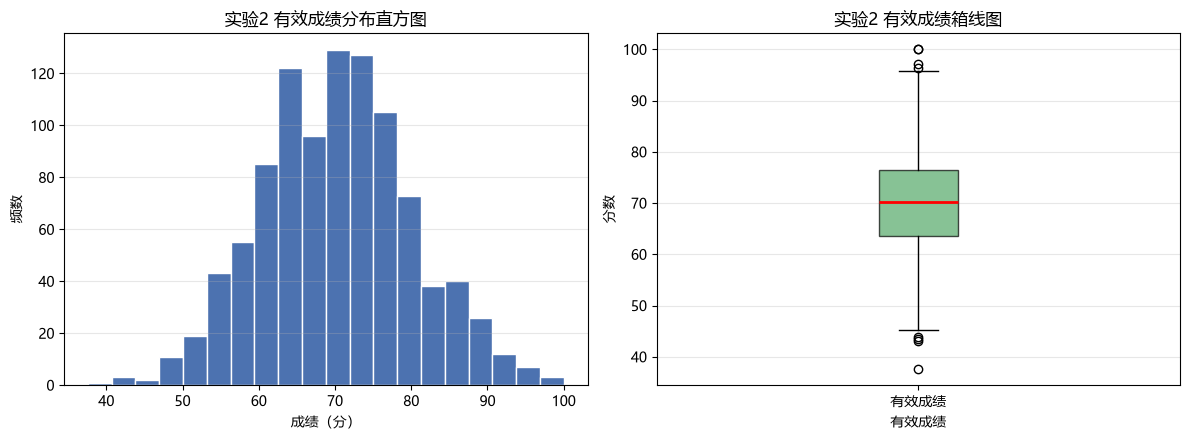

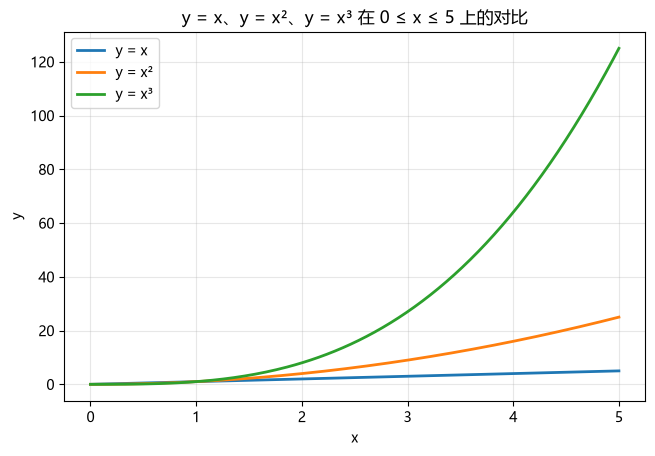


说明：
- 直方图（bins=20）反映成绩的整体分布，大致呈钟形并集中在 70 分附近；
- 箱线图展示中位数、上下四分位数、须线与离群点，可与直方图互相印证；
- 折线图把三条曲线画在同一坐标系中并用图例区分：0 ≤ x < 1 时 x ≥ x² ≥ x³，
  x > 1 后顺序反转，x³ 增长最快；
- 所有图像都通过 plt.show() 直接在 Notebook 中内联显示，未调用 savefig 保存文件。



In [17]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False      # 正常显示负号

print("任务 5：Matplotlib 可视化（直方图 + 箱线图 + 折线图）")

# 实验2 中的“有效成绩”：剔除 np.nan 后的成绩
valid_scores = scores_nan[~np.isnan(scores_nan)]
print(f"有效成绩个数 = {valid_scores.size}，均值 = {valid_scores.mean():.4f}，"
      f"标准差 = {valid_scores.std():.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# ① 直方图
axes[0].hist(valid_scores, bins=20, color="#4C72B0", edgecolor="white")
axes[0].set_title("实验2 有效成绩分布直方图")
axes[0].set_xlabel("成绩（分）")
axes[0].set_ylabel("频数")
axes[0].grid(axis="y", alpha=0.3)

# ② 箱线图
axes[1].boxplot(valid_scores, patch_artist=True,
                boxprops=dict(facecolor="#55A868", alpha=0.7),
                medianprops=dict(color="red", linewidth=2))
axes[1].set_title("实验2 有效成绩箱线图")
axes[1].set_xlabel("有效成绩")
axes[1].set_ylabel("分数")
axes[1].set_xticks([1])
axes[1].set_xticklabels(["有效成绩"])
axes[1].grid(axis="y", alpha=0.3)

fig.tight_layout()
plt.show()

# ③ 折线图：y = x, y = x^2, y = x^3, 0 <= x <= 5
x = np.linspace(0, 5, 200)

fig2, ax = plt.subplots(figsize=(7.5, 4.8))
ax.plot(x, x,     label="y = x",    linewidth=2)
ax.plot(x, x**2,  label="y = x²",   linewidth=2)
ax.plot(x, x**3,  label="y = x³",   linewidth=2)
ax.set_title("y = x、y = x²、y = x³ 在 0 ≤ x ≤ 5 上的对比")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

print("""
说明：
- 直方图（bins=20）反映成绩的整体分布，大致呈钟形并集中在 70 分附近；
- 箱线图展示中位数、上下四分位数、须线与离群点，可与直方图互相印证；
- 折线图把三条曲线画在同一坐标系中并用图例区分：0 ≤ x < 1 时 x ≥ x² ≥ x³，
  x > 1 后顺序反转，x³ 增长最快；
- 所有图像都通过 plt.show() 直接在 Notebook 中内联显示，未调用 savefig 保存文件。
""")


# 实验4：pandas Series、DataFrame 与内存中的
CSV 读写
操作任务：
1. 使⽤以下模拟数据创建 DataFrame，⾏索引为姓名；计算 Total（三科总分）和
Average（三科平均分）两列。输出⾏索引、列名、前 3 ⾏和基本统计信息。

records = {
 
 "Name": ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],
 
 "Group": ["A", "A", "B", "B", "A", "B"],
 
 "Math": [88, 72, 91, 65, 79, 84],
 
 "English": [90, 68, 85, 73, 92, 77],
 
 "Python": [95, 80, 89, 70, 86, 82],

}

2. 分别⽤ loc 和 iloc 读取 Carol 的记录，并筛选平均分不低于 80 的学⽣。
3. 分别⽤ mean(axis=0) 和 mean(axis=1) 计算三科成绩的列均值和每名学⽣的
⾏均值。
4. 使⽤ apply() 计算每名学⽣的三科最⾼分，使⽤ agg() ⼀次得到每科的最⼩值、
均值和最⼤值。任选⼀列使⽤ rank() 给学⽣排名。
5. 按 Group 分组，统计每组⼈数和三科平均分。再⽤ transform('mean') 为每⾏
增加其所在组的 Python 平均分。
3x + y = 9 x + 2y = 8
x
2 − 2 = 0
f(x) = x
2 + x + 2
y = x y =
x
2 y = x
3 0 ≤ x ≤ 56. ⽤ filter() 保留 Python 平均分不低于 80 的组；输出保留的组和学⽣。
7. 计算三科成绩之间的协⽅差矩阵和⽪尔森相关系数矩阵；选择其中⼀对科⽬，解释
协⽅差符号与相关系数⼤⼩的含义。

In [18]:
import numpy as np
import pandas as pd

print("任务 1：创建 DataFrame，行索引为姓名，并计算 Total 与 Average")

records = {
    "Name": ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],
    "Group": ["A", "A", "B", "B", "A", "B"],
    "Math": [88, 72, 91, 65, 79, 84],
    "English": [90, 68, 85, 73, 92, 77],
    "Python": [95, 80, 89, 70, 86, 82],
}

subjects = ["Math", "English", "Python"]

df = pd.DataFrame(records).set_index("Name")     # 行索引 = 姓名
df["Total"] = df[subjects].sum(axis=1)           # 三科总分
df["Average"] = df[subjects].mean(axis=1)        # 三科平均分

print("\n① 行索引 index =", list(df.index))
print("② 列名 columns =", list(df.columns))
print("\n③ 前 3 行 df.head(3):")
print(df.head(3))
print("\n④ 基本统计信息 df.describe():")
print(df[subjects + ["Total", "Average"]].describe().round(4))
print("\n⑤ 完整数据:")
print(df)

print("""
说明：
- pd.DataFrame(dict) 把字典的键当作列名；set_index("Name") 后再指定行标签，
  于是 df.loc["Carol"] 可以直接按姓名取行；
- Total / Average 都是“按行（axis=1）”对三科求和/求均值得到的。
""")


任务 1：创建 DataFrame，行索引为姓名，并计算 Total 与 Average

① 行索引 index = ['Alice', 'Bob', 'Carol', 'David', 'Eva', 'Frank']
② 列名 columns = ['Group', 'Math', 'English', 'Python', 'Total', 'Average']

③ 前 3 行 df.head(3):
      Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Bob       A    72       68      80    220  73.333333
Carol     B    91       85      89    265  88.333333

④ 基本统计信息 df.describe():
          Math  English   Python     Total  Average
count   6.0000   6.0000   6.0000    6.0000   6.0000
mean   79.8333  80.8333  83.6667  244.3333  81.4444
std     9.9079   9.6626   8.5479   25.7811   8.5937
min    65.0000  68.0000  70.0000  208.0000  69.3333
25%    73.7500  74.0000  80.5000  225.7500  75.2500
50%    81.5000  81.0000  84.0000  250.0000  83.3333
75%    87.0000  88.7500  88.2500  263.0000  87.6667
max    91.0000  92.0000  95.0000  273.0000  91.0000

⑤ 完整数据:
      Group  Math  English 

In [19]:
print("任务 2：用 loc 和 iloc 读取 Carol 的记录，并筛选平均分不低于 80 的学生")

carol_loc = df.loc["Carol"]      # 按行标签
carol_iloc = df.iloc[2]          # 按整数位置（Carol 是第 3 行，位置 2）

print("\n① df.loc['Carol']（标签索引）:")
print(carol_loc)
print("\n② df.iloc[2]（位置索引）:")
print(carol_iloc)
print("\n两者内容是否相同:", carol_loc.equals(carol_iloc))

good = df[df["Average"] >= 80]
print("\n③ df[df['Average'] >= 80] 平均分不低于 80 的学生:")
print(good)
print("\n人数 =", len(good), " 名单 =", list(good.index))

print("""
说明：
- loc 用“标签”定位，iloc 用“位置”定位；本例索引是姓名，
  所以 Carol 用 loc["Carol"]，而它在 0 起算的位置上是 2；
- 布尔索引 df[条件] 会返回满足条件的行子集，并保留原来的行索引标签；
- 注意 loc 的切片是“闭区间”（包含末端），iloc 的切片与 Python 一致（不含末端）。
""")


任务 2：用 loc 和 iloc 读取 Carol 的记录，并筛选平均分不低于 80 的学生

① df.loc['Carol']（标签索引）:
Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object

② df.iloc[2]（位置索引）:
Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object

两者内容是否相同: True

③ df[df['Average'] >= 80] 平均分不低于 80 的学生:
      Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Carol     B    91       85      89    265  88.333333
Eva       A    79       92      86    257  85.666667
Frank     B    84       77      82    243  81.000000

人数 = 4  名单 = ['Alice', 'Carol', 'Eva', 'Frank']

说明：
- loc 用“标签”定位，iloc 用“位置”定位；本例索引是姓名，
  所以 Carol 用 loc["Carol"]，而它在 0 起算的位置上是 2；
- 布尔索引 df[条件] 会返回满足条件的行子集，并保留原来的行索引标签；
- 注意 loc 的切片是“闭区间”（包含末端），iloc 的切片与 Python 一致（不含末端）。

In [20]:
print("任务 3：mean(axis=0) 与 mean(axis=1) 的区别")

col_mean = df[subjects].mean(axis=0)   # 沿行方向压缩 -> 得到每列的均值
row_mean = df[subjects].mean(axis=1)   # 沿列方向压缩 -> 得到每行的均值

print("\n① df[subjects].mean(axis=0) 每科列均值:")
print(col_mean.round(4))

print("\n② df[subjects].mean(axis=1) 每名学生的行均值:")
print(row_mean.round(4))

print("\n③ 行均值与任务 1 的 Average 列是否一致:", np.allclose(row_mean, df["Average"]))
print("④ 列均值之和 = %.4f，行均值之和 = %.4f" % (col_mean.sum(), row_mean.sum()))

print("""
说明：
- axis=0 表示“沿着行的方向（向下）压缩”，结果长度等于列数，即每列一个均值；
- axis=1 表示“沿着列的方向（向右）压缩”，结果长度等于行数，即每行一个均值；
- 记忆方法：axis=k 就是“把第 k 个维度压掉”，所以 axis=0 压掉行、axis=1 压掉列。
""")


任务 3：mean(axis=0) 与 mean(axis=1) 的区别

① df[subjects].mean(axis=0) 每科列均值:
Math       79.8333
English    80.8333
Python     83.6667
dtype: float64

② df[subjects].mean(axis=1) 每名学生的行均值:
Name
Alice    91.0000
Bob      73.3333
Carol    88.3333
David    69.3333
Eva      85.6667
Frank    81.0000
dtype: float64

③ 行均值与任务 1 的 Average 列是否一致: True
④ 列均值之和 = 244.3333，行均值之和 = 488.6667

说明：
- axis=0 表示“沿着行的方向（向下）压缩”，结果长度等于列数，即每列一个均值；
- axis=1 表示“沿着列的方向（向右）压缩”，结果长度等于行数，即每行一个均值；
- 记忆方法：axis=k 就是“把第 k 个维度压掉”，所以 axis=0 压掉行、axis=1 压掉列。



In [21]:
print("任务 4：apply() 求每名学生的三科最高分，agg() 一次汇总，rank() 排名")

# ① apply(axis=1)：对每一行（每名学生）应用函数
df["Highest"] = df[subjects].apply(lambda row: row.max(), axis=1)
print("\n① 每名学生的三科最高分（apply + axis=1）:")
print(df[["Math", "English", "Python", "Highest"]])

# ② agg()：一次得到每科的最小值、均值、最大值
agg_result = df[subjects].agg(["min", "mean", "max"])
print("\n② 每科 min / mean / max（agg 一次得到三个统计量）:")
print(agg_result.round(4))

# ③ rank()：给某一列排名（成绩越高名次越靠前）
df["Rank_Python"] = df["Python"].rank(ascending=False, method="min").astype(int)
print("\n③ 按 Python 成绩排名（rank，ascending=False，并列取最小名次）:")
print(df[["Python", "Rank_Python"]].sort_values("Python", ascending=False))

print("""
说明：
- apply(func, axis=1) 把每一行作为 Series 传给 func，适合“逐行自定义计算”；
- agg([...]) 可以在一次调用中传入多个统计量名称，返回以统计量为行索引的 DataFrame，
  比逐个调用 min()/mean()/max() 更简洁；
- rank() 默认升序（值越小名次越靠前），本例成绩排名用 ascending=False；
  method="min" 表示并列时都取较小名次（也可选 dense / average / first）。
""")


任务 4：apply() 求每名学生的三科最高分，agg() 一次汇总，rank() 排名

① 每名学生的三科最高分（apply + axis=1）:
       Math  English  Python  Highest
Name                                 
Alice    88       90      95       95
Bob      72       68      80       80
Carol    91       85      89       91
David    65       73      70       73
Eva      79       92      86       92
Frank    84       77      82       84

② 每科 min / mean / max（agg 一次得到三个统计量）:
         Math  English   Python
min   65.0000  68.0000  70.0000
mean  79.8333  80.8333  83.6667
max   91.0000  92.0000  95.0000

③ 按 Python 成绩排名（rank，ascending=False，并列取最小名次）:
       Python  Rank_Python
Name                      
Alice      95            1
Carol      89            2
Eva        86            3
Frank      82            4
Bob        80            5
David      70            6

说明：
- apply(func, axis=1) 把每一行作为 Series 传给 func，适合“逐行自定义计算”；
- agg([...]) 可以在一次调用中传入多个统计量名称，返回以统计量为行索引的 DataFrame，
  比逐个调用 min()/mean()/max() 更简洁；
- rank() 默认升序（值越小名次越靠前），本例成绩排名用 ascendin

In [22]:
print("任务 5：按 Group 分组统计人数与三科平均分，并用 transform('mean') 广播组均值")

grouped = df.groupby("Group")

# ① 每组人数
count_by_group = grouped.size().rename("人数")
print("\n① 每组人数:")
print(count_by_group)

# ② 每组三科平均分
mean_by_group = grouped[subjects].mean()
print("\n② 每组三科平均分:")
print(mean_by_group.round(4))

# ③ transform：把组统计量按原行顺序广播回每一行
df["GroupPythonMean"] = grouped["Python"].transform("mean")
print("\n③ 每行新增所在组的 Python 平均分（transform('mean')）:")
print(df[["Group", "Python", "GroupPythonMean"]])
print("\n行数是否保持不变:", len(df) == 6, "；各组的组均值:",
      df.groupby("Group")["GroupPythonMean"].first().round(4).to_dict())

print("""
说明：
- groupby("Group").size() / mean() 是“聚合”：每组只剩一行，行数从 6 变成 2；
- transform("mean") 是“组内变换”：对每一行返回它所属组的均值，行数和顺序都不变，
  所以能直接 df["新列"] = ... 赋值；
- 常见误区：把 mean() 的结果直接赋给列会因索引不匹配而得到 NaN，必须用 transform 或 map。
""")


任务 5：按 Group 分组统计人数与三科平均分，并用 transform('mean') 广播组均值

① 每组人数:
Group
A    3
B    3
Name: 人数, dtype: int64

② 每组三科平均分:
          Math  English   Python
Group                           
A      79.6667  83.3333  87.0000
B      80.0000  78.3333  80.3333

③ 每行新增所在组的 Python 平均分（transform('mean')）:
      Group  Python  GroupPythonMean
Name                                
Alice     A      95        87.000000
Bob       A      80        87.000000
Carol     B      89        80.333333
David     B      70        80.333333
Eva       A      86        87.000000
Frank     B      82        80.333333

行数是否保持不变: True ；各组的组均值: {'A': 87.0, 'B': 80.3333}

说明：
- groupby("Group").size() / mean() 是“聚合”：每组只剩一行，行数从 6 变成 2；
- transform("mean") 是“组内变换”：对每一行返回它所属组的均值，行数和顺序都不变，
  所以能直接 df["新列"] = ... 赋值；
- 常见误区：把 mean() 的结果直接赋给列会因索引不匹配而得到 NaN，必须用 transform 或 map。



In [24]:
print("任务 6：用 filter() 保留 Python 平均分不低于 80 的组")

group_py_mean = df.groupby("Group")["Python"].mean()
print("\n各组 Python 平均分:")
print(group_py_mean.round(4))

kept_groups = group_py_mean[group_py_mean >= 80].index.tolist()
dropped_groups = [g for g in group_py_mean.index if g not in kept_groups]
print("\n① 保留的组:", kept_groups)
print("   被过滤掉的组:", dropped_groups if dropped_groups else "无")

# ② groupby + filter：按“组级条件”筛选，返回满足条件组中的全部原始行
kept_students = df.groupby("Group").filter(lambda g: g["Python"].mean() >= 80)
print("\n② df.groupby('Group').filter(...) 保留的学生:")
print(kept_students[["Group", "Python", "Average"]])

# ③ 补充：把阈值提高到 85，便于观察 filter 真正剔除组的效果
kept_85 = df.groupby("Group").filter(lambda g: g["Python"].mean() >= 85)
print("\n③ 补充演示：阈值提高到 85 后保留的学生:")
print(kept_85[["Group", "Python", "Average"]])

print("""
说明：
- filter(func) 中的 func 接收“每个组的小表（DataFrame）”，返回 True/False；
  返回 True 的组会保留其全部原始行（行数不会只变成每组一行，这点与 agg 不同）；
- 本数据 A 组 Python 均值 87.0、B 组 80.3，都 ≥ 80，所以阈值为 80 时两组全部保留；
  阈值提高到 85 时只剩 A 组，可直观看到过滤效果；
- 若只要组级结果，用 groupby().mean() 再布尔筛选即可；若要保留明细行，用 filter。
""")


任务 6：用 filter() 保留 Python 平均分不低于 80 的组

各组 Python 平均分:
Group
A    87.0000
B    80.3333
Name: Python, dtype: float64

① 保留的组: ['A', 'B']
   被过滤掉的组: 无

② df.groupby('Group').filter(...) 保留的学生:
      Group  Python    Average
Name                          
Alice     A      95  91.000000
Bob       A      80  73.333333
Carol     B      89  88.333333
David     B      70  69.333333
Eva       A      86  85.666667
Frank     B      82  81.000000

③ 补充演示：阈值提高到 85 后保留的学生:
      Group  Python    Average
Name                          
Alice     A      95  91.000000
Bob       A      80  73.333333
Eva       A      86  85.666667

说明：
- filter(func) 中的 func 接收“每个组的小表（DataFrame）”，返回 True/False；
  返回 True 的组会保留其全部原始行（行数不会只变成每组一行，这点与 agg 不同）；
- 本数据 A 组 Python 均值 87.0、B 组 80.3，都 ≥ 80，所以阈值为 80 时两组全部保留；
  阈值提高到 85 时只剩 A 组，可直观看到过滤效果；
- 若只要组级结果，用 groupby().mean() 再布尔筛选即可；若要保留明细行，用 filter。



In [25]:
print("任务 7：三科成绩的协方差矩阵与皮尔逊相关系数矩阵")

cov_matrix = df[subjects].cov()                       # 默认 ddof=1，样本协方差
corr_matrix = df[subjects].corr(method="pearson")     # 皮尔逊相关系数

print("\n① 协方差矩阵 df[subjects].cov():")
print(cov_matrix.round(4))

print("\n② 皮尔逊相关系数矩阵 df[subjects].corr(method='pearson'):")
print(corr_matrix.round(4))

print("\n③ 以 Math 与 Python 这一对科目为例:")
print(f"   cov(Math, Python) = {cov_matrix.loc['Math', 'Python']:.4f}   （> 0，同向变化）")
print(f"   r  (Math, Python) = {corr_matrix.loc['Math', 'Python']:.4f}   （接近 1，强正相关）")

print("""
说明：
- 协方差公式 cov(X, Y) = Σ(xi - x̄)(yi - ȳ) / (n - 1)：
  符号表示线性关系方向 —— 正号同增同减、负号此增彼减、接近 0 表示没有明显线性关系；
  但数值大小受量纲（分数单位）影响，不能直接用来比较相关强弱；
- 相关系数 r = cov(X, Y) / (s_X · s_Y)，是标准化后的协方差，取值 [-1, 1]，
  无量纲：|r| 越接近 1 线性关系越强，越接近 0 越弱；
- 本例 Math 与 Python 的协方差为正（≈ 75），说明数学好的学生 Python 通常也好；
  相关系数 ≈ 0.88，属于较强的正线性相关，但相关不等于因果；
- 协方差/相关矩阵都对称，且对角线分别是各科方差与 1（自身与自身完全相关）。
""")


任务 7：三科成绩的协方差矩阵与皮尔逊相关系数矩阵

① 协方差矩阵 df[subjects].cov():
            Math  English   Python
Math     98.1667  62.5667  74.9333
English  62.5667  93.3667  62.5333
Python   74.9333  62.5333  73.0667

② 皮尔逊相关系数矩阵 df[subjects].corr(method='pearson'):
           Math  English  Python
Math     1.0000   0.6535  0.8848
English  0.6535   1.0000  0.7571
Python   0.8848   0.7571  1.0000

③ 以 Math 与 Python 这一对科目为例:
   cov(Math, Python) = 74.9333   （> 0，同向变化）
   r  (Math, Python) = 0.8848   （接近 1，强正相关）

说明：
- 协方差公式 cov(X, Y) = Σ(xi - x̄)(yi - ȳ) / (n - 1)：
  符号表示线性关系方向 —— 正号同增同减、负号此增彼减、接近 0 表示没有明显线性关系；
  但数值大小受量纲（分数单位）影响，不能直接用来比较相关强弱；
- 相关系数 r = cov(X, Y) / (s_X · s_Y)，是标准化后的协方差，取值 [-1, 1]，
  无量纲：|r| 越接近 1 线性关系越强，越接近 0 越弱；
- 本例 Math 与 Python 的协方差为正（≈ 75），说明数学好的学生 Python 通常也好；
  相关系数 ≈ 0.88，属于较强的正线性相关，但相关不等于因果；
- 协方差/相关矩阵都对称，且对角线分别是各科方差与 1（自身与自身完全相关）。

